# Balance de pérdida: condición inicial y frontera

Dos selectores: poda parcial de k y reconstrucción, con PCA + media al 95 %, QR directo, candidatos fijos, 20 snapshots cada cinco pasos del último intervalo de cien y 128 activos. Diez semillas, 100 pasos uniformes comunes y 10000 de continuación.

Se cambia únicamente la pérdida después del warmup, conservando los momentos de Adam. baseline = datos + PDE + IC; ic10 = datos + PDE + 10 IC; bc1 = datos + PDE + IC + BC. No se combinan todavía IC10 y BC: estos controles separan los efectos. El peso 10 se fija como contraste exploratorio, no como óptimo. Las referencias baseline se reutilizan de notebooks 21 y 19. Las historias divergen después del cambio de pérdida, como efecto del entrenamiento adaptativo.

BC es la media del error cuadrado en x=−1 y x=1 con objetivo cero; se usan los tiempos supervisados del batch de entrenamiento, compartidos entre selectores. No se usan tiempos de prueba para imponer frontera. La condición inicial mantiene 32 nodos distribuidos. El término BC añade restricciones al objetivo y costo de derivación; no se afirma igualdad de costo computacional.

| Pérdida | Selector | RMSE prueba ± DE | Residuo RMS | RMSE IC | RMS BC |
|---|---|---:|---:|---:|---:|
| baseline | prune | 0.09870 ± 0.02202 | 0.08080 | 0.12944 | 0.06951 |
| baseline | rebuild | 0.07144 ± 0.00977 | 0.16801 | 0.08991 | 0.04528 |
| ic10 | prune | 0.11811 ± 0.04965 | 0.14749 | 0.04062 | 0.03201 |
| ic10 | rebuild | 0.05941 ± 0.01769 | 0.23165 | 0.02473 | 0.01349 |
| bc1 | prune | 0.10155 ± 0.03341 | 0.08776 | 0.11239 | 0.01855 |
| bc1 | rebuild | 0.08146 ± 0.00903 | 0.17661 | 0.09097 | 0.01194 |


ic10 / prune frente a su baseline: diferencia media RMSE +0.01942; mejora en 3/10 semillas.

ic10 / rebuild frente a su baseline: diferencia media RMSE -0.01203; mejora en 8/10 semillas.

bc1 / prune frente a su baseline: diferencia media RMSE +0.00285; mejora en 6/10 semillas.

bc1 / rebuild frente a su baseline: diferencia media RMSE +0.01002; mejora en 2/10 semillas.

**Validación**

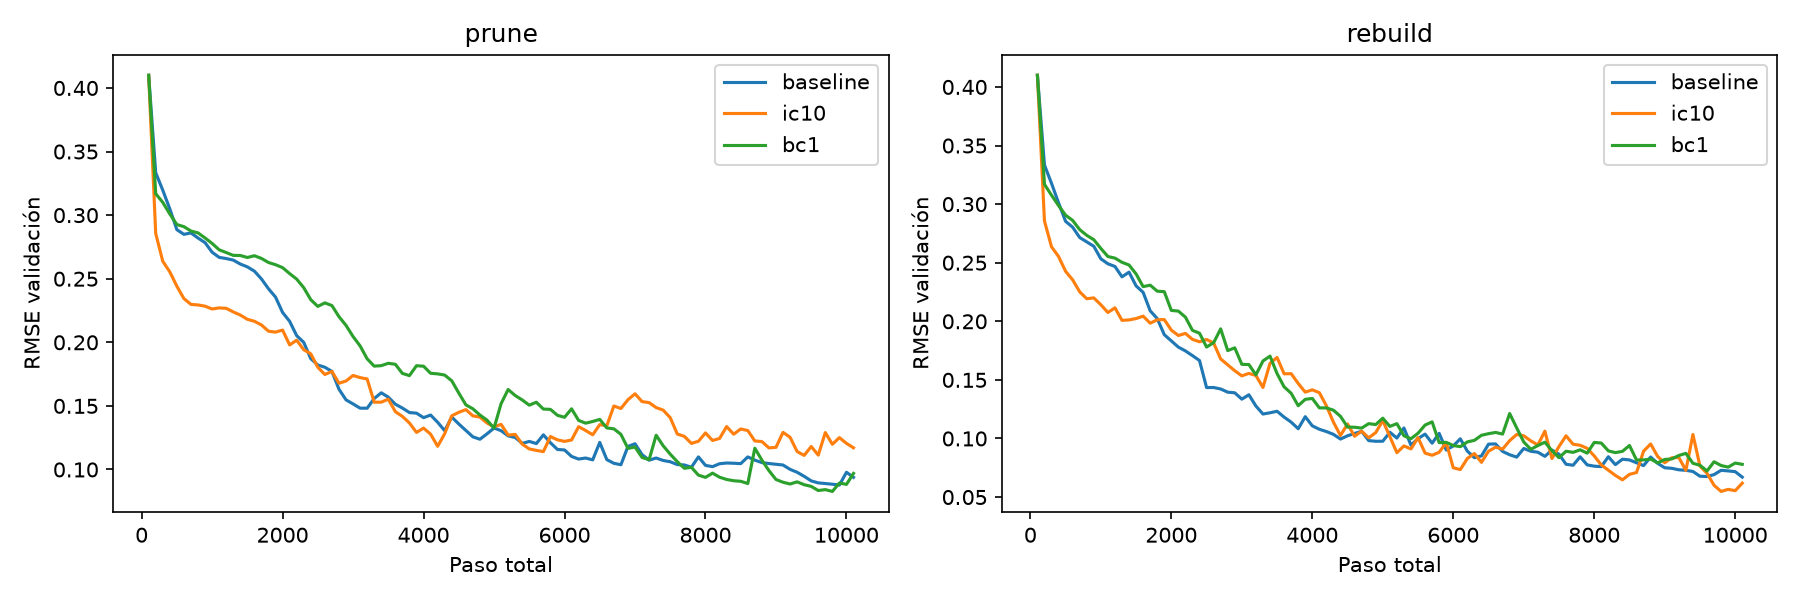

In [ ]:
from pathlib import Path
from IPython.display import Image, display
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pyproject.toml').is_file())
display(Image(filename=str(ROOT / 'pca_collocation/results/burgers/loss_balance/ic_bc_controls_10_seeds_10k_v1/comparison.png'), format='png', embed=True))


Los modelos se evalúan al presupuesto terminal, sin seleccionar por prueba. La desviación representa dispersión entre semillas. components.csv registra valores sin ponderar, normas de gradiente y normas ponderadas, y cosenos PDE–IC y PDE–BC en los pasos 100, 1100, 5100 y 10100. Los monitores usan el mismo batch supervisado/IC de referencia y 128 puntos físicos independientes fijos por semilla, para comparar redes sin confundir el lote adaptativo. Son diagnósticos locales de gradiente: no prueban por sí solos causalidad ni describen todo el entrenamiento. Las referencias reutilizadas no tienen este diagnóstico adicional, lo que se mantiene explícito en manifest.json.

Reproducir: `python scripts/run_collocation_loss_balance.py`. Se reutilizan corridas completas. Esta prueba cambia el objetivo tras el warmup; no reproduce las condiciones duras del artículo. Si un control mejora, conviene confirmarlo con nuevas semillas y estudiar sensibilidad de pesos antes de adoptarlo.

## Diagnóstico final de gradientes

| Pérdida | Selector | Norma PDE | Norma IC ponderada | Norma BC ponderada | Coseno PDE–IC | Coseno PDE–BC |
|---|---|---:|---:|---:|---:|---:|
| ic10 | prune | 1.6738 | 1.4479 | 0.0000 | -0.3070 | 0.1765 |
| ic10 | rebuild | 6.4073 | 0.5314 | 0.0000 | -0.1273 | 0.0919 |
| bc1 | prune | 1.0444 | 0.3823 | 0.1510 | -0.4207 | 0.2761 |
| bc1 | rebuild | 3.4167 | 0.2668 | 0.0773 | -0.3333 | 0.2343 |

Promedios entre semillas sobre el probe común al paso final. Un coseno negativo indica oposición local de gradientes, no demuestra por sí solo la causa del error de solución. La magnitud de una componente de pérdida no equivale a la magnitud de su gradiente.